# 05 — Explainable AI (XAI): Menjelaskan Skor TOPSIS dan Penugasan Klaster

**Input:** `Data/topsis_result.csv` · `Data/clustered_result.csv` · `Data/dki_master.csv`  
**Output:** `Data/xai_global.csv` · `Data/xai_local.csv` · `Data/xai_cluster.csv` · `Data/xai_cluster_importance.csv` · `Data/figures/final/fig08`–`fig11`

Notebook ini menjawab dua pertanyaan yang biasanya muncul setelah ranking dan klaster terbentuk:

1. **Mengapa skor TOPSIS sebuah kecamatan tinggi atau rendah?**  
   Dijawab dengan **nilai Shapley eksak** atas 8 kriteria. Karena hanya ada $2^8 = 256$ koalisi, seluruh kontribusi dapat dihitung persis tanpa model pengganti dan tanpa aproksimasi sampling.
2. **Mengapa sebuah kecamatan masuk klaster tertentu?**  
   Dijawab dengan **kepentingan fitur partisi K-Means** dan **dekomposisi margin jarak** ke klaster pesaing terdekat.

> **Prinsip penting:** XAI tidak mengubah model, bobot, atau keputusan. Ia hanya membuka “kotak hitam” agar pembuat kebijakan dapat melihat kriteria mana yang menggerakkan skor dan fitur mana yang menahan sebuah kecamatan di klasternya.


## 0. Setup

Notebook memakai `src/topsis.py` untuk menghitung ulang skor dan `src/xai.py` untuk nilai Shapley serta penjelasan K-Means. Tidak ada library XAI tambahan (mis. SHAP/LIME) yang perlu dipasang: untuk 8 kriteria, enumerasi Shapley eksak lebih akurat dan sepenuhnya transparan.


In [1]:
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT))

from src.topsis import shannon_entropy_weights, topsis
from src.xai import (
    boundary_cases,
    cluster_assignment_contributions,
    exact_shapley_topsis,
    explain_local,
    kmeans_feature_importance,
    shapley_global_importance,
)

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11, "axes.titleweight": "bold",
    "axes.titlesize": 13, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .25, "grid.linestyle": "--",
    "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.pad_inches": .15,
    "figure.facecolor": "white", "axes.facecolor": "white",
})

DATA = ROOT / "Data"
FIG = DATA / "figures" / "final"
FIG.mkdir(parents=True, exist_ok=True)

PALETTE = {"Prioritas Tinggi": "#8B0000", "Waspada": "#E4572E", "Menengah": "#F6C85F", "Rendah": "#B7E4A7"}
LABEL_ORDER = list(PALETTE)
DIM_COLORS = {"Bahaya": "#b91c1c", "Kerentanan": "#c2410c", "Kapasitas": "#0369a1"}
NOTE, EDGE = "#64748b", "#cbd5e1"

PRETTY = {
    "frek_tahun_banjir": "Frekuensi\ntahun banjir",
    "bulan_banjir_per_tahun": "Bulan banjir\n/tahun",
    "kejadian_per_tahun": "Kejadian\n/tahun",
    "tinggi_max_cm": "Tinggi maks\ngenangan",
    "lama_hari_mean": "Lama\ngenangan",
    "jiwa_per_1000": "Jiwa terdampak\n/1000",
    "kepadatan_jiwa_km2": "Kepadatan\npenduduk",
    "n_alat_dini": "Alat peringatan\ndini (cost)",
}
print("Output figure:", FIG)


Output figure: C:\Users\amkag\.vscode\GeoPulse-id\Geopulse-id\Data\figures\final


## 1. Muat Data, Reproduksi Skor TOPSIS, dan Siapkan Fitur Klaster

Skor TOPSIS dihitung ulang dari 8 kriteria dengan bobot Shannon Entropy, lalu di-*assert* identik dengan `topsis_result.csv`. Fitur klaster direkonstruksi dengan langkah yang sama seperti `03_kmeans.ipynb` (log1p, winsorize 5%, standardisasi z-score) agar penjelasan K-Means dapat dihitung meskipun file interim belum tersedia.


In [2]:
topsis_df = pd.read_csv(DATA / "topsis_result.csv")
topsis_df["kecamatan"] = topsis_df.kecamatan.str.strip().str.upper()
topsis_df = topsis_df.set_index("kecamatan")

clustered = pd.read_csv(DATA / "clustered_result.csv")
clustered["kecamatan"] = clustered.kecamatan.str.strip().str.upper()
clustered = clustered.set_index("kecamatan")

master = pd.read_csv(DATA / "dki_master.csv", index_col="kecamatan")
master.index = master.index.str.strip().str.upper()
master = master[~master.wilayah.str.contains("SERIBU", na=False)].copy()
master = master.join(topsis_df[["skor_topsis", "rank_topsis"]], how="inner")
assert len(master) == 42, f"Jumlah kecamatan daratan = {len(master)}, seharusnya 42"

CRITERIA = {
    "frek_tahun_banjir":      {"dimensi": "Bahaya",     "type": "benefit", "satuan": "proporsi (0-1)", "desc": "Proporsi tahun terjadi banjir"},
    "bulan_banjir_per_tahun": {"dimensi": "Bahaya",     "type": "benefit", "satuan": "bulan/tahun",    "desc": "Rata-rata bulan banjir per tahun"},
    "kejadian_per_tahun":     {"dimensi": "Bahaya",     "type": "benefit", "satuan": "kejadian/tahun", "desc": "Frekuensi banjir tahunan"},
    "tinggi_max_cm":          {"dimensi": "Bahaya",     "type": "benefit", "satuan": "cm",             "desc": "Ketinggian genangan maksimal"},
    "lama_hari_mean":         {"dimensi": "Bahaya",     "type": "benefit", "satuan": "hari",           "desc": "Rata-rata durasi genangan"},
    "jiwa_per_1000":          {"dimensi": "Bahaya",     "type": "benefit", "satuan": "jiwa/1000 pddk", "desc": "Penduduk terdampak per 1000 warga"},
    "kepadatan_jiwa_km2":     {"dimensi": "Kerentanan", "type": "benefit", "satuan": "jiwa/km2",       "desc": "Kepadatan penduduk wilayah"},
    "n_alat_dini":            {"dimensi": "Kapasitas",  "type": "cost",    "satuan": "unit EWS",       "desc": "Jumlah alat peringatan dini (EWS)"},
}
cols = list(CRITERIA)
types = [CRITERIA[c]["type"] for c in cols]
X = topsis_df.loc[master.index, cols].values.astype(float)
w_entropy = shannon_entropy_weights(X)
score = topsis(X, w_entropy, types)[0]
assert np.allclose(score, topsis_df.loc[master.index, "skor_topsis"].values, atol=1e-9), "skor TOPSIS tidak identik"

# --- rekonstruksi fitur klaster persis seperti 03_kmeans.ipynb ---
CAND = ["skor_topsis", "jiwa_per_1000", "kepadatan_jiwa_km2"]
Xc = master[CAND].copy()
Xc = Xc.fillna(Xc.median())
q1, q3 = Xc.quantile(.25), Xc.quantile(.75)
outlier = (Xc < q1 - 1.5 * (q3 - q1)) | (Xc > q3 + 1.5 * (q3 - q1))
LOG = [k for k in Xc.columns if k != "skor_topsis" and Xc[k].skew() > 1 and (Xc[k] >= 0).all()]
Xt = Xc.copy()
Xt[LOG] = np.log1p(Xt[LOG])
for k in Xc.columns[outlier.any()]:
    if k != "skor_topsis":
        lo, hi = Xt[k].quantile([.05, .95])
        Xt[k] = Xt[k].clip(lo, hi)
corr = Xt.corr().abs()
drop = set()
for i, a in enumerate(corr.columns):
    for b in corr.columns[i + 1:]:
        if corr.loc[a, b] > .90 and a not in drop and b not in drop:
            drop.add(b)
FEATURES = [k for k in Xt.columns if k not in drop]
Z = pd.DataFrame(StandardScaler().fit_transform(Xt[FEATURES]), index=Xt.index, columns=FEATURES)
Z.index.name = "kecamatan"
labels = clustered.loc[Z.index, "cluster_id"].values
name_map = clustered[["cluster_id", "cluster_name"]].drop_duplicates().set_index("cluster_id").cluster_name.to_dict()
cluster_label = np.array([name_map[int(c)] for c in labels])
assert np.allclose(clustered.loc[Z.index, "skor_topsis"], topsis_df.loc[Z.index, "skor_topsis"], atol=1e-12)

print(f"Data siap: {len(Z)} kecamatan x {len(cols)} kriteria | fitur klaster: {FEATURES}")
print("Skor TOPSIS direproduksi persis. Rentang:", f"{score.min():.3f}–{score.max():.3f}")


Data siap: 42 kecamatan x 8 kriteria | fitur klaster: ['skor_topsis', 'jiwa_per_1000', 'kepadatan_jiwa_km2']
Skor TOPSIS direproduksi persis. Rentang: 0.160–0.832


## 2. XAI Global TOPSIS — Nilai Shapley Eksak per Kriteria

TOPSIS diperlakukan sebagai permainan kooperatif dengan 8 kriteria sebagai pemain. Untuk setiap koalisi $S$, kriteria di luar $S$ diganti dengan **profil acuan teraman**:

- kriteria *benefit* (bahaya/kerentanan) memakai nilai minimum dataset;
- kriteria *cost* (kapasitas EWS) memakai nilai maksimum dataset.

Profil ini memiliki skor $C_i = 0$, sehingga nilai Shapley tiap kriteria dapat dibaca sebagai **kontribusi kenaikan skor dari kondisi teraman menuju kondisi aktual**:

$$\phi_j(x)=\sum_{S\subseteq N\setminus\{j\}}\frac{|S|!\,(n-|S|-1)!}{n!}\left[v(S\cup\{j\})-v(S)\right]$$

dengan $v(S)$ = skor TOPSIS memakai nilai aktual untuk kriteria di $S$ dan nilai profil teraman untuk kriteria lainnya. Karena $n=8$, seluruh $2^8$ koalisi dienumerasi sehingga hasilnya **eksak** dan memenuhi:

$$\sum_{j=1}^{8}\phi_j(x)=C_i(x)-C_i(\text{profil teraman})=C_i(x)$$


In [3]:
phi = exact_shapley_topsis(
    X, w_entropy, types,
    feature_names=cols,
    index=topsis_df.loc[master.index].index,
)
base_value = phi.attrs["base_value"]
prediction = pd.Series(phi.attrs["prediction"], index=phi.index)
assert abs(base_value) < 1e-9, "profil teraman seharusnya memiliki skor 0"
assert np.allclose(phi.sum(axis=1), prediction, atol=1e-9), "efisiensi Shapley tidak terpenuhi"
assert np.allclose(prediction.values, topsis_df.loc[prediction.index, "skor_topsis"].values, atol=1e-9)

global_imp = shapley_global_importance(phi, weights=w_entropy, criteria_meta=CRITERIA)
global_imp.index.name = "kriteria"
display(global_imp.round(4))
print(f"Total |kontribusi| per kecamatan (rata-rata): {global_imp.rata_rata_abs.sum():.4f}")
print("Kriteria paling dominan:", global_imp.index[0], f"({global_imp.share_abs.iloc[0]:.1%} dari total |φ|)")


,rata_rata_abs,rata_rata_bertanda,std,n,share_abs,bobot,dimensi,tipe
kriteria,,,,,,,,
n_alat_dini,0.5097,0.5097,0.1766,42,0.8532,0.4784,Kapasitas,cost
jiwa_per_1000,0.0473,0.0473,0.0638,42,0.0792,0.2206,Bahaya,benefit
kejadian_per_tahun,0.0155,0.0155,0.0136,42,0.0259,0.0979,Bahaya,benefit
bulan_banjir_per_tahun,0.0117,0.0117,0.0092,42,0.0195,0.0793,Bahaya,benefit
lama_hari_mean,0.0055,0.0055,0.0034,42,0.0093,0.0368,Bahaya,benefit
tinggi_max_cm,0.0037,0.0037,0.0024,42,0.0062,0.0379,Bahaya,benefit
kepadatan_jiwa_km2,0.0031,0.0031,0.0040,42,0.0052,0.0359,Kerentanan,benefit
frek_tahun_banjir,0.0009,0.0009,0.0003,42,0.0015,0.0131,Bahaya,benefit


Total |kontribusi| per kecamatan (rata-rata): 0.5974
Kriteria paling dominan: n_alat_dini (85.3% dari total |φ|)


**Cara membaca.** `rata_rata_abs` mengukur seberapa besar kriteria itu menggerakkan skor TOPSIS di 42 kecamatan. `rata_rata_bertanda` menunjukkan arah: positif berarti menaikkan urgensi, negatif berarti menurunkan. `share_abs` adalah porsi kriteria terhadap total pergerakan skor. Bandingkan kolom `bobot` dengan `share_abs`: bobot besar belum tentu menjadi penjelas dominan bila polanya seragam atau berinteraksi kuat dengan kriteria lain.


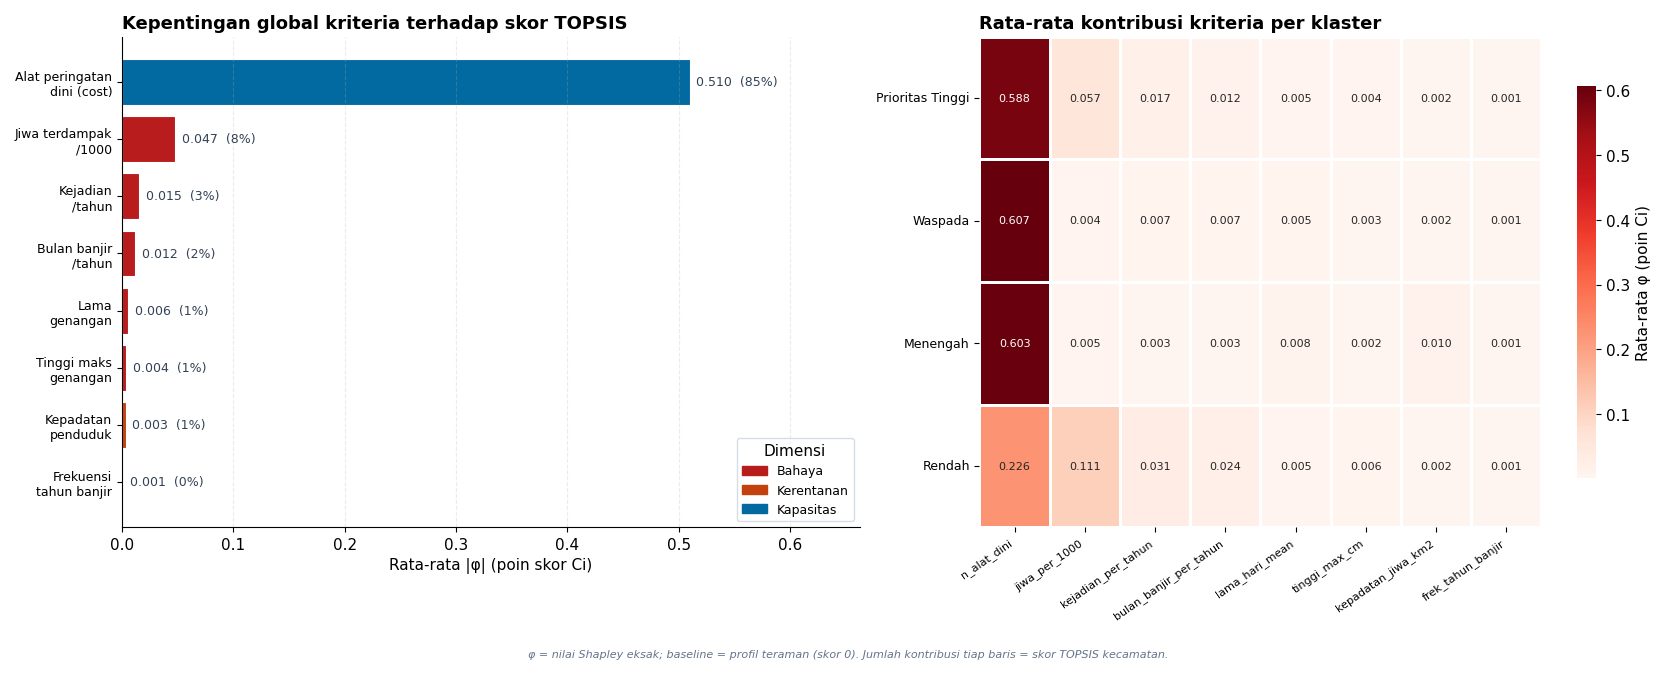

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6.4), gridspec_kw={"width_ratios": [1.05, 1]})
ax = axes[0]
order = global_imp.index[::-1]
vals = global_imp.loc[order, "rata_rata_abs"]
colors = [DIM_COLORS.get(CRITERIA[c]["dimensi"], "#64748b") for c in order]
bars = ax.barh(np.arange(len(order)), vals, color=colors, edgecolor="white", linewidth=.8)
for b, c, v in zip(bars, order, vals):
    ax.text(v + vals.max() * .012, b.get_y() + b.get_height() / 2,
            f"{v:.3f}  ({global_imp.loc[c, 'share_abs']:.0%})", va="center", fontsize=9, color="#334155")
ax.set_yticks(np.arange(len(order)))
ax.set_yticklabels([PRETTY.get(c, c) for c in order], fontsize=9)
ax.set_xlabel("Rata-rata |φ| (poin skor Ci)")
ax.set_xlim(0, vals.max() * 1.30)
ax.set_title("Kepentingan global kriteria terhadap skor TOPSIS", loc="left")
ax.grid(axis="y", visible=False)
ax.legend(handles=[mpatches.Patch(color=v, label=k) for k, v in DIM_COLORS.items()],
          title="Dimensi", frameon=True, edgecolor=EDGE, fontsize=9, loc="lower right")

ax = axes[1]
by_cluster = phi.groupby(cluster_label).mean().reindex(LABEL_ORDER)[global_imp.index]
sns.heatmap(by_cluster, annot=True, fmt=".3f", cmap="Reds", linewidths=.8, linecolor="white",
            cbar_kws={"label": "Rata-rata φ (poin Ci)", "shrink": .8}, ax=ax, annot_kws={"fontsize": 8})
ax.set_title("Rata-rata kontribusi kriteria per klaster", loc="left")
ax.set_xlabel("")
ax.set_ylabel("")
plt.setp(ax.get_xticklabels(), rotation=35, ha="right", fontsize=8)
plt.setp(ax.get_yticklabels(), rotation=0, fontsize=9)
ax.grid(False)

fig.text(.5, -.03, "φ = nilai Shapley eksak; baseline = profil teraman (skor 0). Jumlah kontribusi tiap baris = skor TOPSIS kecamatan.",
         ha="center", fontsize=8, style="italic", color=NOTE)
plt.tight_layout()
plt.savefig(FIG / "fig08_xai_global_shapley.png")
plt.show()


## 3. XAI Global — Sebaran Kontribusi (Beeswarm)

Grafik beeswarm memperlihatkan **setiap kecamatan sebagai satu titik**. Posisi horizontal adalah kontribusi kriteria terhadap skor, sedangkan warna adalah z-score nilai kriteria tersebut. Pola yang lebar berarti kriteria itu membedakan kecamatan dengan kuat; pola yang sempit berarti kontribusinya relatif seragam.


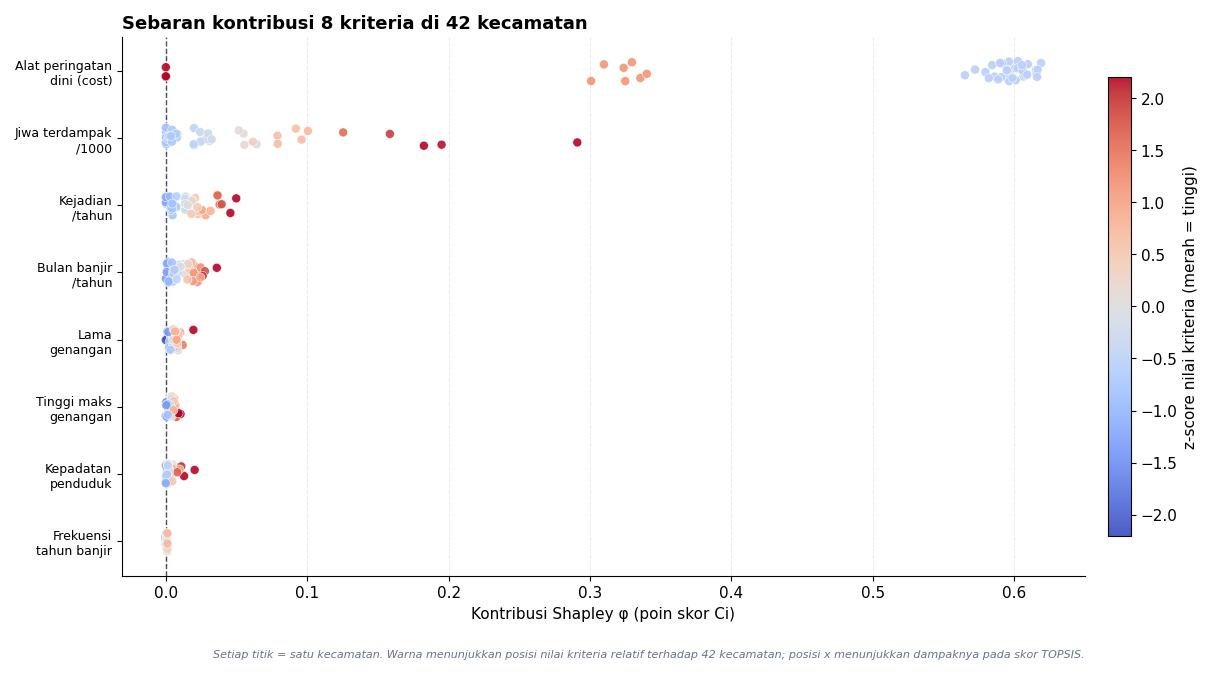

In [5]:
raw = pd.DataFrame(X, index=phi.index, columns=cols)
raw_z = (raw - raw.mean()) / raw.std(ddof=0)
long = phi.rename_axis("kecamatan").reset_index().melt(id_vars="kecamatan", var_name="kriteria", value_name="kontribusi")
long["z"] = [raw_z.loc[r.kecamatan, r.kriteria] for r in long.itertuples()]
long["kriteria"] = pd.Categorical(long.kriteria, categories=list(global_imp.index), ordered=True)

rng = np.random.default_rng(42)
xs, ys, cs = [], [], []
for yi, crit in enumerate(global_imp.index):
    sub = long[long.kriteria == crit]
    xs.extend(sub.kontribusi.values)
    ys.extend(yi + rng.uniform(-.16, .16, len(sub)))
    cs.extend(sub.z.values)

fig, ax = plt.subplots(figsize=(13, 6.4))
sc = ax.scatter(xs, ys, c=cs, cmap="coolwarm", vmin=-2.2, vmax=2.2, s=42,
                edgecolor="white", linewidth=.4, alpha=.9, zorder=3)
ax.axvline(0, color="#334155", lw=1, ls="--", zorder=1)
ax.set_yticks(np.arange(len(global_imp)))
ax.set_yticklabels([PRETTY.get(c, c) for c in global_imp.index], fontsize=9)
ax.set_xlabel("Kontribusi Shapley φ (poin skor Ci)")
ax.set_title("Sebaran kontribusi 8 kriteria di 42 kecamatan", loc="left")
ax.grid(axis="y", visible=False)
ax.invert_yaxis()
cb = fig.colorbar(sc, ax=ax, pad=.02, shrink=.85)
cb.set_label("z-score nilai kriteria (merah = tinggi)")
fig.text(.5, -.03, "Setiap titik = satu kecamatan. Warna menunjukkan posisi nilai kriteria relatif terhadap 42 kecamatan; posisi x menunjukkan dampaknya pada skor TOPSIS.",
         ha="center", fontsize=8, style="italic", color=NOTE)
plt.tight_layout()
plt.savefig(FIG / "fig09_xai_beeswarm.png")
plt.show()


## 4. XAI Lokal — Mengapa Kebon Jeruk Menjadi Peringkat 1?

Nilai Shapley bersifat aditif, sehingga penjelasan satu kecamatan dapat divisualisasikan sebagai **waterfall**: mulai dari skor profil teraman (0), lalu menambahkan kontribusi tiap kriteria sampai mencapai skor TOPSIS aktual. Tabel di bawah juga membandingkan lima kecamatan teratas.


In [6]:
top5 = topsis_df.nsmallest(5, "rank_topsis").index.tolist()
local_top5 = phi.loc[top5].copy()
local_top5.insert(0, "skor_topsis", topsis_df.loc[top5, "skor_topsis"])
local_top5.insert(1, "rank_topsis", topsis_df.loc[top5, "rank_topsis"].astype(int))
local_top5.insert(2, "cluster_name", clustered.loc[top5, "cluster_name"])
display(local_top5.round(3))

alt = top5[0]
row = phi.loc[alt]
local = explain_local(phi, alt)
print(f"{alt.title()} | peringkat #{int(topsis_df.loc[alt, 'rank_topsis'])} | Ci = {topsis_df.loc[alt, 'skor_topsis']:.3f}")
print(local.round(4).to_string())


,skor_topsis,rank_topsis,cluster_name,frek_tahun_banjir,bulan_banjir_per_tahun,kejadian_per_tahun,tinggi_max_cm,lama_hari_mean,jiwa_per_1000,kepadatan_jiwa_km2,n_alat_dini
kecamatan,,,,,,,,,,,
KEBON JERUK,0.832,1,Prioritas Tinggi,0.001,0.023,0.038,0.003,0.005,0.195,0.002,0.565
TANJUNG PRIOK,0.717,2,Prioritas Tinggi,0.001,0.008,0.016,0.001,0.008,0.100,0.001,0.582
TANAH ABANG,0.707,3,Prioritas Tinggi,0.000,0.005,0.005,0.006,0.009,0.096,0.002,0.584
PENJARINGAN,0.693,4,Prioritas Tinggi,0.001,0.015,0.037,0.005,0.006,0.056,0.000,0.572
CILANDAK,0.685,5,Prioritas Tinggi,0.001,0.022,0.023,0.004,0.003,0.052,0.001,0.580


Kebon Jeruk | peringkat #1 | Ci = 0.832
                        kontribusi  abs_kontribusi  share_abs  kumulatif
n_alat_dini                 0.5652          0.5652     0.6791     0.5652
jiwa_per_1000               0.1950          0.1950     0.2343     0.7602
kejadian_per_tahun          0.0380          0.0380     0.0457     0.7982
bulan_banjir_per_tahun      0.0230          0.0230     0.0276     0.8212
lama_hari_mean              0.0048          0.0048     0.0057     0.8260
tinggi_max_cm               0.0030          0.0030     0.0036     0.8290
kepadatan_jiwa_km2          0.0023          0.0023     0.0028     0.8313
frek_tahun_banjir           0.0010          0.0010     0.0012     0.8323


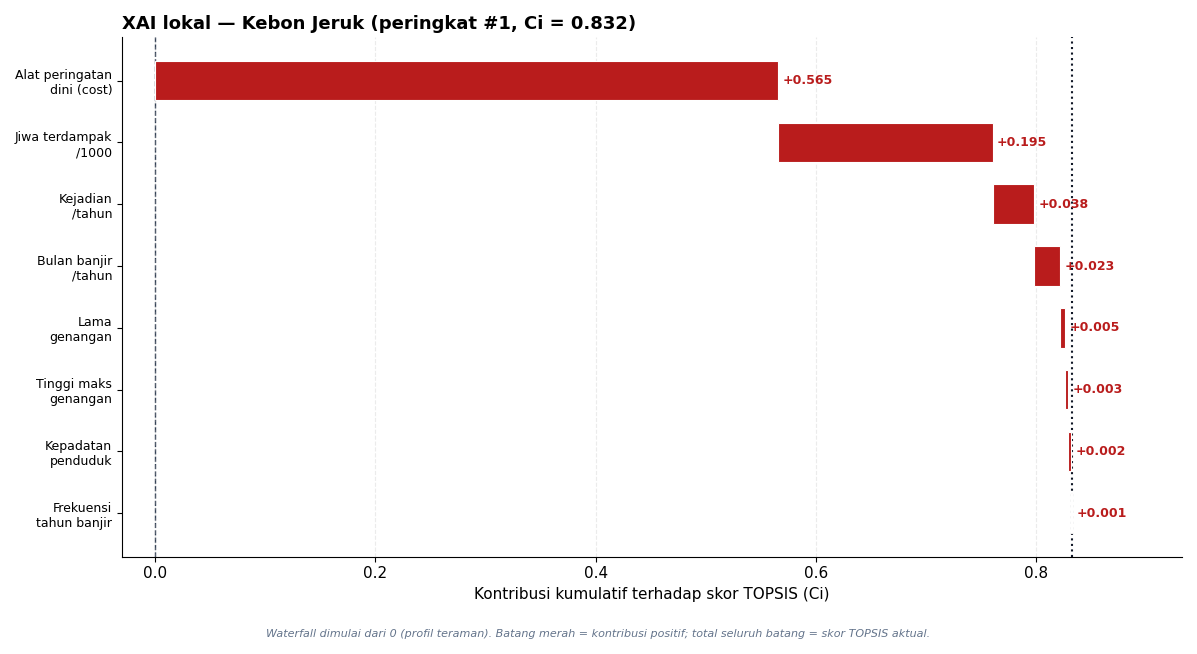

In [7]:
order = row.abs().sort_values(ascending=False).index
vals = row.loc[order]
cum = 0.0
fig, ax = plt.subplots(figsize=(12, 6.2))
for i, (crit, v) in enumerate(vals.items()):
    color = "#b91c1c" if v >= 0 else "#0369a1"
    ax.barh(i, v, left=cum, color=color, edgecolor="white", linewidth=.8, height=.64, zorder=3)
    tx = cum + v + (0.004 if v >= 0 else -0.004)
    ax.text(tx, i, f"{v:+.3f}", va="center", ha="left" if v >= 0 else "right",
            fontsize=9, fontweight="bold", color=color)
    cum += v
ax.axvline(0, color="#334155", lw=1, ls="--", zorder=1)
ax.axvline(cum, color="#111827", lw=1.5, ls=":", zorder=1)
ax.set_yticks(np.arange(len(order)))
ax.set_yticklabels([PRETTY.get(c, c) for c in order], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("Kontribusi kumulatif terhadap skor TOPSIS (Ci)")
lo = min(0, vals.min(), cum)
hi = max(vals.max(), cum)
ax.set_xlim(lo - .03, hi * 1.12)
ax.set_title(f"XAI lokal — {alt.title()} (peringkat #{int(topsis_df.loc[alt, 'rank_topsis'])}, Ci = {cum:.3f})", loc="left")
ax.grid(axis="y", visible=False)
fig.text(.5, -.03, "Waterfall dimulai dari 0 (profil teraman). Batang merah = kontribusi positif; total seluruh batang = skor TOPSIS aktual.",
         ha="center", fontsize=8, style="italic", color=NOTE)
plt.tight_layout()
plt.savefig(FIG / "fig10_xai_lokal_kebon_jeruk.png")
plt.show()


## 5. XAI K-Means — Fitur Pendukung dan Kecamatan Batas

Dua pertanyaan dijawab pada bagian ini:

1. **Fitur mana yang membentuk partisi klaster?**  
   Menggunakan *between-cluster sum of squares* (SSB):

   $$SSB_j=\sum_k n_k(\mu_{kj}-\mu_j)^2$$

   `share` = proporsi SSB fitur terhadap total, sedangkan `eta2` = proporsi variansi fitur yang dijelaskan klaster.
2. **Mengapa sebuah kecamatan berada di klaster itu dan bukan di klaster tetangganya?**  
   Untuk kecamatan $i$ di klaster $k$ dengan pesaing terdekat $l$:

   $$margin_i=||z_i-c_k||^2-||z_i-c_l||^2=\sum_j\left[(z_{ij}-c_{kj})^2-(z_{ij}-c_{lj})^2\right]$$

   Kontribusi fitur **negatif** berarti fitur tersebut menahan kecamatan di klaster sendiri; **positif** berarti mendorongnya ke klaster pesaing. Semakin dekat margin ke 0, semakin batas penugasannya.


In [8]:
cluster_imp = kmeans_feature_importance(Z, labels)
cluster_imp.index.name = "fitur"

centers = np.vstack([Z.values[labels == k].mean(0) for k in range(len(name_map))])
assign = cluster_assignment_contributions(Z, labels, centers=centers, cluster_names=name_map)

low_sil = clustered.loc[Z.index, "silhouette_sample"].nsmallest(6).index
bound = boundary_cases(assign, n=6, index=low_sil)
print("Batas penugasan (margin negatif = lebih dekat ke klaster sendiri):")
display(bound[["klaster", "klaster_pesaing", "margin"]].round(3))
display(cluster_imp.round(3))


Batas penugasan (margin negatif = lebih dekat ke klaster sendiri):


,klaster,klaster_pesaing,margin
kecamatan,,,
KEBAYORAN LAMA,3,1,-1.999
TEBET,3,0,-1.730
CEMPAKA PUTIH,1,2,-0.437
KELAPA GADING,1,0,-0.402
CAKUNG,0,1,-0.301
GROGOL PETAMBURAN,1,0,-0.288


,ss_between,share,eta2
fitur,,,
skor_topsis,32.882,0.384,0.783
jiwa_per_1000,31.491,0.367,0.750
kepadatan_jiwa_km2,21.341,0.249,0.508


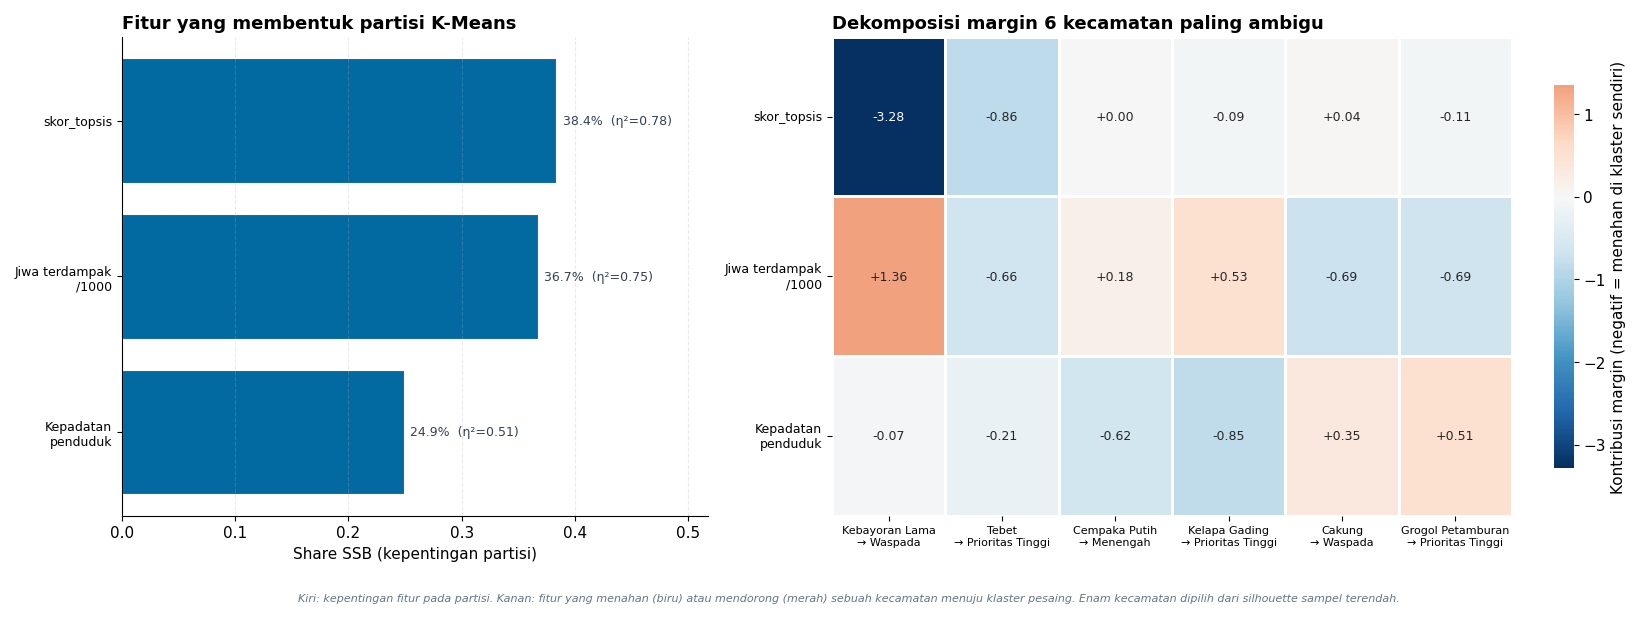

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.8), gridspec_kw={"width_ratios": [1, 1.45]})

ax = axes[0]
ord_ = cluster_imp.index[::-1]
vals = cluster_imp.loc[ord_, "share"]
bars = ax.barh(np.arange(len(ord_)), vals, color="#0369a1", edgecolor="white", linewidth=.8)
for b, f_, v in zip(bars, ord_, vals):
    ax.text(v + vals.max() * .015, b.get_y() + b.get_height() / 2,
            f"{v:.1%}  (η²={cluster_imp.loc[f_, 'eta2']:.2f})", va="center", fontsize=9, color="#334155")
ax.set_yticks(np.arange(len(ord_)))
ax.set_yticklabels([PRETTY.get(f_, f_) for f_ in ord_], fontsize=9)
ax.set_xlim(0, vals.max() * 1.35)
ax.set_xlabel("Share SSB (kepentingan partisi)")
ax.set_title("Fitur yang membentuk partisi K-Means", loc="left")
ax.grid(axis="y", visible=False)

ax = axes[1]
mat = bound[list(Z.columns)].T
xt = [f"{idx.title()}\n→ {name_map[int(c)]}" for idx, c in zip(bound.index, bound.klaster_pesaing)]
sns.heatmap(mat, annot=True, fmt="+.2f", cmap="RdBu_r", center=0, linewidths=.8, linecolor="white",
            cbar_kws={"label": "Kontribusi margin (negatif = menahan di klaster sendiri)", "shrink": .8},
            xticklabels=xt, yticklabels=[PRETTY.get(f_, f_) for f_ in Z.columns],
            ax=ax, annot_kws={"fontsize": 9})
ax.set_title("Dekomposisi margin 6 kecamatan paling ambigu", loc="left")
ax.set_xlabel("")
ax.set_ylabel("")
plt.setp(ax.get_xticklabels(), rotation=0, fontsize=8)
plt.setp(ax.get_yticklabels(), rotation=0, fontsize=9)
ax.grid(False)

fig.text(.5, -.04, "Kiri: kepentingan fitur pada partisi. Kanan: fitur yang menahan (biru) atau mendorong (merah) sebuah kecamatan menuju klaster pesaing. Enam kecamatan dipilih dari silhouette sampel terendah.",
         ha="center", fontsize=8, style="italic", color=NOTE)
plt.tight_layout()
plt.savefig(FIG / "fig11_xai_klaster.png")
plt.show()


## 6. Validasi dan Ekspor

Pemeriksaan yang dilakukan:

- efisiensi Shapley: $\sum_j \phi_{ij}=C_i$ (sudah di-assert pada bagian 2);
- konsistensi skor hasil hitung ulang dengan `topsis_result.csv`;
- korelasi antara kepentingan XAI dan bobot entropy — untuk menunjukkan bahwa bobot besar tidak otomatis menjadi penjelas dominan;
- kestabilan kepentingan global terhadap pilihan baseline (profil teraman vs profil rata-rata).


In [10]:
rho_bobot = spearmanr(global_imp.rata_rata_abs, global_imp.bobot)[0]
print(f"Spearman(kepentingan XAI, bobot entropy) = {rho_bobot:.3f}")

phi_mean = exact_shapley_topsis(X, w_entropy, types, feature_names=cols, index=phi.index, baseline=X.mean(axis=0))
imp_mean = shapley_global_importance(phi_mean)
rho_base = spearmanr(global_imp.loc[cols, "rata_rata_abs"], imp_mean.loc[cols, "rata_rata_abs"])[0]
print(f"Spearman(kepentingan baseline aman, baseline rata-rata) = {rho_base:.3f}")
print(f"Efisiensi baseline rata-rata: max |sum(phi) - (Ci - C_baseline)| = "
      f"{np.abs(phi_mean.sum(axis=1) - (prediction - phi_mean.attrs['base_value'])).max():.2e}")

local_long = phi.rename_axis(index="kecamatan", columns="kriteria").stack().rename("kontribusi").reset_index()
raw_long = raw.rename_axis(index="kecamatan", columns="kriteria").stack().rename("nilai").reset_index()
z_long = raw_z.rename_axis(index="kecamatan", columns="kriteria").stack().rename("z").reset_index()
local_long = local_long.merge(raw_long, on=["kecamatan", "kriteria"]).merge(z_long, on=["kecamatan", "kriteria"])
local_long["skor_topsis"] = local_long.kecamatan.map(topsis_df.skor_topsis)
local_long["rank_topsis"] = local_long.kecamatan.map(topsis_df.rank_topsis).astype(int)
local_long["cluster_name"] = local_long.kecamatan.map(clustered.cluster_name)
local_long.to_csv(DATA / "xai_local.csv", index=False)
global_imp.rename_axis("kriteria").to_csv(DATA / "xai_global.csv")

cluster_long = assign.rename_axis(index="kecamatan", columns="fitur").stack().rename("kontribusi").reset_index()
cluster_long["klaster"] = np.repeat(assign.attrs["own_cluster"], len(Z.columns))
cluster_long["klaster_pesaing"] = np.repeat(assign.attrs["competitor"], len(Z.columns))
cluster_long["margin"] = np.repeat(assign.attrs["margin"], len(Z.columns))
cluster_long["cluster_name"] = cluster_long.klaster.map(name_map)
cluster_long.to_csv(DATA / "xai_cluster.csv", index=False)
cluster_imp.rename_axis("fitur").to_csv(DATA / "xai_cluster_importance.csv")

print("\\nFile tersimpan:")
for f in [DATA / "xai_global.csv", DATA / "xai_local.csv", DATA / "xai_cluster.csv", DATA / "xai_cluster_importance.csv"]:
    print(f"  {f.name:32s} {f.stat().st_size / 1024:7.1f} KB")


Spearman(kepentingan XAI, bobot entropy) = 0.976
Spearman(kepentingan baseline aman, baseline rata-rata) = 1.000
Efisiensi baseline rata-rata: max |sum(phi) - (Ci - C_baseline)| = 2.78e-16


\nFile tersimpan:
  xai_global.csv                       1.2 KB
  xai_local.csv                       36.3 KB
  xai_cluster.csv                     10.1 KB
  xai_cluster_importance.csv           0.2 KB


## 7. Ringkasan Temuan

Notebook ini sengaja **tidak mengubah** keputusan yang sudah dibuat pada tahap TOPSIS dan K-Means. Nilai tambahnya adalah transparansi:

- **TOPSIS:** nilai Shapley eksak memecah skor $C_i$ menjadi kontribusi 8 kriteria yang aditif. Pembaca dapat melihat apakah tingginya skor sebuah kecamatan disebabkan oleh bahaya, dampak kemanusiaan, kepadatan, atau minimnya kapasitas EWS.
- **K-Means:** kepentingan fitur partisi dan dekomposisi margin menunjukkan fitur mana yang membentuk klaster serta fitur mana yang menahan kecamatan batas di klasternya.
- **Limitasi bobot entropi menjadi terlihat:** jika satu kriteria mendominasi, XAI akan menampilkan dominasi itu secara eksplisit, bukan menyembunyikannya di balik skor akhir.

### Batasan interpretasi

1. Nilai Shapley menjelaskan **alokasi skor model**, bukan efek kausal kebijakan. Menambah EWS tidak otomatis menurunkan skor sebesar nilai kontribusinya karena bobot entropy akan berubah bila data berubah.
2. Baseline “profil teraman” adalah konstruksi analitis dari nilai ekstrem dataset, bukan target kebijakan nyata.
3. Dekomposisi margin K-Means menjelaskan jarak terhadap centroid pada ruang fitur terstandar, bukan penyebab sosial-ekonomi penugasan klaster.
4. XAI tidak memperbaiki dominasi bobot `n_alat_dini`; ia hanya membuat dominasi tersebut eksplisit. Untuk kebijakan, tetap bandingkan skema bobot entropy dengan bobot pakar/equal pada `02_topsis.ipynb`.


In [11]:
print("Ringkasan XAI")
print("-" * 68)
print(f"Kriteria paling dominan : {global_imp.index[0]} ({global_imp.share_abs.iloc[0]:.1%} dari total |φ|)")
print(f"Kontribusi rata-rata    : {global_imp.rata_rata_abs.iloc[0]:.3f} poin Ci")
print(f"Skor rata-rata TOPSIS   : {score.mean():.3f}")
alt = topsis_df.nsmallest(1, "rank_topsis").index[0]
print(f"Contoh lokal teratas    : {alt.title()} = {topsis_df.loc[alt, 'skor_topsis']:.3f}")
print(f"Kecamatan batas         : {', '.join([x.title() for x in bound.index])}")
print("-" * 68)
for f in sorted(FIG.glob("fig08*.png")) + sorted(FIG.glob("fig09*.png")) + sorted(FIG.glob("fig10*.png")) + sorted(FIG.glob("fig11*.png")):
    print(f"{f.name:38s} {os.path.getsize(f) / 1024:7.1f} KB")


Ringkasan XAI
--------------------------------------------------------------------
Kriteria paling dominan : n_alat_dini (85.3% dari total |φ|)
Kontribusi rata-rata    : 0.510 poin Ci
Skor rata-rata TOPSIS   : 0.597
Contoh lokal teratas    : Kebon Jeruk = 0.832
Kecamatan batas         : Kebayoran Lama, Tebet, Cempaka Putih, Kelapa Gading, Cakung, Grogol Petamburan
--------------------------------------------------------------------
fig08_xai_global_shapley.png             449.4 KB
fig09_xai_beeswarm.png                   341.0 KB
fig10_xai_lokal_kebon_jeruk.png          213.4 KB
fig11_xai_klaster.png                    315.6 KB
